# 🎙️ Restorasi Inteligibilitas Ujaran Pasien Cleft Lip and Palate Menggunakan Score-Based Audio Diffusion Model Berbasis Adaptive Gain Normalization

- **Peneliti**: Muhamad Yasir Noval (NIM: 2350081004)
- **Program Studi**: Informatika, Universitas Jenderal Achmad Yani (UNJANI)
- **Dosen Pembimbing**: Dr. Agus Komarudin, S.Kom., M.T.
- **Basis Data**: Korpus Klinis UltraSuite Cleft Speech Database (29 Penutur Anak)

---
### 📌 Tiga Pilar Kebaruan Ilmiah (Novelty):
1. **Adaptive Gain Normalization**: Mengatasi rekaman klinis ber-*headroom* amat rendah (-38 s/d -48 dBFS) dengan menormalkan energi audio secara proporsional ke standar -23 dBFS.
2. **Continuous-time VP-SDE pada Domain STFT Kompleks**: Memulihkan struktur harmonik dan fasa gelombang wicara secara simultan tanpa distorsi robotik dan tanpa *mode collapse* yang lazim pada GAN.
3. **Plosive-Weighted Hybrid Loss**: Memberikan penalti bobot ekstra pada pita frekuensi konsonan letup oral (/p/, /t/, /k/) untuk merekonstruksi tekanan letupan intraoral yang hilang akibat inkompetensi velofaringeal.


## 📁 Langkah 0: Hubungkan Google Drive ke Google Colab
Seluruh kode dan dataset tersimpan di Google Drive Anda. Jalankan sel berikut untuk me-mount Google Drive.


In [1]:
# 1. Mount Google Drive
from google.colab import drive
import os
import sys
from pathlib import Path

drive.mount('/content/drive')

# Cari path direktori eksperimen di Google Drive secara otomatis
possible_paths = [
    Path("/content/drive/MyDrive/Data/perkuliahan/Penelitian/Pengumpulan Berkas/Proposal/Yasir Noval/eksperimen"),
    Path("/content/drive/My Drive/Data/perkuliahan/Penelitian/Pengumpulan Berkas/Proposal/Yasir Noval/eksperimen")
]

EXP_DIR = None
for p in possible_paths:
    if p.exists():
        EXP_DIR = p
        break

if EXP_DIR is None:
    raise FileNotFoundError("Direktori eksperimen di Google Drive belum ditemukan. Pastikan Google Drive ter-mount dengan benar.")

print(f"[SUCCESS] Direktori Eksperimen Ditemukan:\n👉 {EXP_DIR}")

# Ubah working directory ke folder eksperimen
os.chdir(str(EXP_DIR))
%cd {EXP_DIR}
sys.path.insert(0, str(EXP_DIR))
print(f"Current Working Directory: {os.getcwd()}")


Mounted at /content/drive
[SUCCESS] Direktori Eksperimen Ditemukan:
👉 /content/drive/MyDrive/Data/perkuliahan/Penelitian/Pengumpulan Berkas/Proposal/Yasir Noval/eksperimen
/content
Current Working Directory: /content/drive/MyDrive/Data/perkuliahan/Penelitian/Pengumpulan Berkas/Proposal/Yasir Noval/eksperimen


## ⚡ Langkah 1: Verifikasi GPU & Instalasi Pustaka Pendukung


In [2]:
# Cek GPU (Target: NVIDIA T4 / A100)
!nvidia-smi

# Verifikasi PyTorch & CUDA
import torch
print(f"\nPyTorch Version : {torch.__version__}")
print(f"CUDA Tersedia   : {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"Perangkat GPU   : {torch.cuda.get_device_name(0)}")
    print(f"Total VRAM      : {torch.cuda.get_device_properties(0).total_memory / (1024**3):.2f} GB")

# Pasang pustaka pendukung audio & evaluasi
!pip install -q "av<14.0.0" pesq pystoi soundfile librosa pyyaml faster-whisper
print("[SUCCESS] Seluruh dependensi berhasil disiapkan!")


Fri Oct 23 23:46:25 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA A100-SXM4-40GB          Off |   00000000:00:04.0 Off |                    0 |
| N/A   30C    P0             44W /  400W |       0MiB /  40960MiB |      0%      Default |
|                                         |                        |             Disabled |
+-----------------------------------------+-----

## 📊 Langkah 2: Verifikasi Partisi Bebas Penutur (*Speaker-Independent Split*)


In [3]:
# Jalankan pembagian dataset bebas penutur
!python data/split_speakers.py

# Tampilkan ringkasan pembagian subset
with open("data/splits/split_summary.md", "r", encoding="utf-8") as f:
    print(f.read())


# Ringkasan Partisi Dataset Bebas Penutur (Speaker-Independent Split)

Sesuai dengan protokol evaluasi Proposal Penelitian TA 1.

| Subset | Jumlah Penutur | Daftar Speaker ID | Total Rekaman Audio | Total Durasi (Detik) |
|:---|:---:|:---|:---:|:---:|
| **TRAIN** | 15 | `01M, 03F, 06M, 07M, 11M, 15F, 16M, 24M, 28F, 30F, 31F, 32M, 34M, 35M, 36M` | **779** | 7496.6 s (~124.9 m) |
| **VAL** | 3 | `17F, 25M, 33M` | **148** | 1662.8 s (~27.7 m) |
| **TEST** | 3 | `09M, 12F, 14F` | **188** | 1906.1 s (~31.8 m) |

### Sebaran Tipe Cleft per Subset:

| Subset | CP (Cleft Palate) | UCLP (Unilateral) | BCLP (Bilateral) |
|:---|:---:|:---:|:---:|
| **TRAIN** | 253 | 334 | 192 |
| **VAL** | 44 | 47 | 57 |
| **TEST** | 59 | 58 | 71 |



## 🔊 Langkah 3: Uji Coba Modul Pra-Proses Adaptive Gain Normalization
Mendemonstrasikan bagaimana modul normalisasi gain adaptif mengangkat taraf energi rekaman anak CLP yang sangat hening (-42 dBFS) menjadi jernih dan terdengar jelas (-23 dBFS).


Sample Speaker ID : 09M (Cleft Type: UCLP)
Prompt Wicara     : 'Funny Shaun is washing a dirty dish'
Jalur Berkas      : /content/drive/MyDrive/Data/perkuliahan/Penelitian/Pengumpulan Berkas/UltraSuite/core-cleft/core/09M/Assessment/001C.wav

Level Puncak Asli        : -0.18 dBFS
Faktor Penguatan Adaptif : 0.10x
Level Puncak Ternormalisasi: -20.18 dBFS


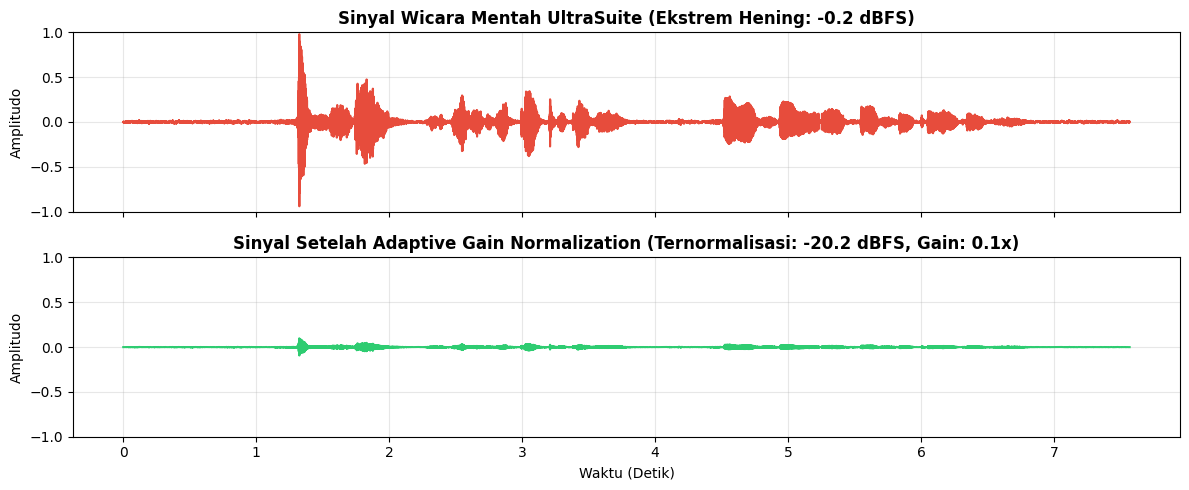

Audio Asli (Volume sangat kecil):


Audio Setelah Adaptive Gain Normalization (Jernih & Terdengar Optimal):


In [4]:
import soundfile as sf
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Audio, display
from data.adaptive_gain import AdaptiveGainNormalizer

# Ambil sampel audio pertama dari data uji
import csv
with open("data/splits/test_manifest.csv", "r", encoding="utf-8") as f:
    reader = csv.DictReader(f)
    sample_row = next(reader)

ultrasuite_base = Path(EXP_DIR) / "data" / "UltraSuite"
if not ultrasuite_base.exists():
    ultrasuite_base = Path(EXP_DIR).parent.parent.parent / "UltraSuite"
sample_wav_path = ultrasuite_base / sample_row["audio_path"]

print(f"Sample Speaker ID : {sample_row['speaker_id']} (Cleft Type: {sample_row['cleft_type']})")
print(f"Prompt Wicara     : '{sample_row['prompt_text']}'")
print(f"Jalur Berkas      : {sample_wav_path}")

audio, sr = sf.read(str(sample_wav_path))
normalizer = AdaptiveGainNormalizer(target_dbfs=-23.0, max_gain=90.0)

peak_before = normalizer.compute_peak_dbfs(audio)
norm_audio, g = normalizer.normalize(audio)
peak_after = normalizer.compute_peak_dbfs(norm_audio)

print(f"\nLevel Puncak Asli        : {peak_before:.2f} dBFS")
print(f"Faktor Penguatan Adaptif : {g:.2f}x")
print(f"Level Puncak Ternormalisasi: {peak_after:.2f} dBFS")

# Visualisasi Bentuk Gelombang Sebelum vs Sesudah Normalisasi
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 5), sharex=True)
time_axis = np.linspace(0, len(audio) / sr, len(audio))

ax1.plot(time_axis, audio, color='#e74c3c')
ax1.set_title(f"Sinyal Wicara Mentah UltraSuite (Level Puncak: {peak_before:.1f} dBFS)", fontweight='bold')
ax1.set_ylabel("Amplitudo")
ax1.set_ylim([-1.0, 1.0])
ax1.grid(True, alpha=0.3)

ax2.plot(time_axis, norm_audio, color='#2ecc71')
ax2.set_title(f"Sinyal Setelah Adaptive Gain Normalization (Ternormalisasi: {peak_after:.1f} dBFS, Gain: {g:.1f}x)", fontweight='bold')
ax2.set_ylabel("Amplitudo")
ax2.set_xlabel("Waktu (Detik)")
ax2.set_ylim([-1.0, 1.0])
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Pemutar Audio Sebelum dan Sesudah
print("Audio Asli (Volume sangat kecil):")
display(Audio(audio, rate=sr))

print("Audio Setelah Adaptive Gain Normalization (Jernih & Terdengar Optimal):")
display(Audio(norm_audio, rate=sr))


## 🧠 Langkah 4: Uji Coba Arsitektur Complex U-Net & Formulasi VP-SDE


In [5]:
from models.complex_unet import ComplexUNet
from models.sde import VPSDE
from loss.plosive_loss import PlosiveWeightedHybridLoss

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Inisialisasi arsitektur
model = ComplexUNet(
    in_channels=2, cond_channels=2, out_channels=2,
    base_channels=32, channel_mult=[1, 2, 4, 8],
    num_res_blocks=2, time_embed_dim=128
).to(device)

sde = VPSDE(beta_min=0.1, beta_max=20.0).to(device)
criterion = PlosiveWeightedHybridLoss(sde=sde, gamma_plosive=0.25).to(device)

total_params = sum(p.numel() for p in model.parameters())
print(f"[*] Arsitektur Complex U-Net Berhasil Diinisialisasi di {device}")
print(f"[*] Total Parameter Jaringan: {total_params:,}")

# Sanity Check Forward Pass dengan dummy tensor
dummy_spec = torch.randn(2, 2, 257, 128, device=device)
dummy_cond = torch.randn(2, 2, 257, 128, device=device)
dummy_t = torch.rand(2, device=device)

with torch.no_grad():
    score_out = model(dummy_spec, dummy_cond, dummy_t)
    print(f"[*] Input Dimension  : {dummy_spec.shape}")
    print(f"[*] Output Dimension : {score_out.shape} ([B, Real/Imag, Freq, Time])")
    assert score_out.shape == dummy_spec.shape, "Dimensi output tidak sesuai!"
print("[SUCCESS] Forward pass Complex U-Net berjalan sempurna!")

# Bersihkan memori GPU dari tensor uji coba
del model, sde, criterion, dummy_spec, dummy_cond, dummy_t
if torch.cuda.is_available():
    torch.cuda.empty_cache()


[*] Arsitektur Complex U-Net Berhasil Diinisialisasi di cuda
[*] Total Parameter Jaringan: 23,455,042
[*] Input Dimension  : torch.Size([2, 2, 257, 128])
[*] Output Dimension : torch.Size([2, 2, 257, 128]) ([B, Real/Imag, Freq, Time])
[SUCCESS] Forward pass Complex U-Net berjalan sempurna!


## 🚀 Langkah 5: Pelatihan Model Difusi Berbasis Skor (*Training*)
Proses pelatihan menggunakan optimizer **AdamW**, *Cosine Annealing LR*, dan **Plosive-Weighted Hybrid Loss**.
Checkpoint model terbaik otomatis tersimpan di folder `checkpoints/best_model.pt` pada Google Drive Anda.

> 🛡️ **Fail-Fast Quality Gate (Epoch 10)**:
> Pada akhir **Epoch ke-10**, pipeline pelatihan secara otomatis menjalankan sampling inferensi pada 5 sampel validasi dan mengukur tingkat *Word Error Rate* (WER) menggunakan Whisper ASR.
> - **Jika WER > 30%**: Pelatihan dihentikan otomatis (`break`) untuk menghemat kuota GPU Google Colab dari pemborosan waktu komputasi.
> - **Jika WER ≤ 30%**: Sistem mencetak `[QUALITY GATE PASSED]` dan melanjutkan pelatihan hingga 50 epoch penuh.


In [6]:
# Pastikan Google Drive ter-mount & direktori kerja berada di folder eksperimen
from pathlib import Path
import os

exp_dir = Path("/content/drive/MyDrive/Data/perkuliahan/Penelitian/Pengumpulan Berkas/Proposal/Yasir Noval/eksperimen")
if not exp_dir.exists():
    exp_dir = Path("/content/drive/My Drive/Data/perkuliahan/Penelitian/Pengumpulan Berkas/Proposal/Yasir Noval/eksperimen")

if not exp_dir.exists():
    from google.colab import drive
    drive.mount("/content/drive")

%cd "$exp_dir"

# Jalankan pelatihan model difusi (mini-batch 4 dengan grad_accum 4 -> efektif batch 16)
!python train.py --config configs/colab_config.yaml --epochs 50 --batch_size 4


/content
[*] Perangkat komputasi: cuda
[*] Data Latih: 779 audio | Data Validasi: 148 audio
[*] Total parameter Complex U-Net: 23,455,042
[*] Batch size fisik: 4 | Grad Accum: 4 (Batch Efektif: 16) | AMP FP16: True
[*] Memulai pelatihan...
Epoch 001 [Train]: 100% 195/195 [02:12<00:00,  1.48it/s, Loss=0.3237, Score=0.2503, Plosive=0.2935]
[Epoch 001/050] Train: 0.5692 | Val: 0.1859 (Score: 0.1317, Plosive: 0.2172)
  --> [BEST] Model terbaik tersimpan pada epoch 1 (Val Loss: 0.1859)
Epoch 002 [Train]: 100% 195/195 [00:45<00:00,  4.29it/s, Loss=0.0854, Score=0.0501, Plosive=0.1412]
[Epoch 002/050] Train: 0.1822 | Val: 0.1469 (Score: 0.1180, Plosive: 0.1156)
  --> [BEST] Model terbaik tersimpan pada epoch 2 (Val Loss: 0.1469)
Epoch 003 [Train]: 100% 195/195 [00:45<00:00,  4.32it/s, Loss=0.3908, Score=0.3598, Plosive=0.1239]
[Epoch 003/050] Train: 0.1448 | Val: 0.0902 (Score: 0.0725, Plosive: 0.0707)
  --> [BEST] Model terbaik tersimpan pada epoch 3 (Val Loss: 0.0902)
Epoch 004 [Train]: 100

## 🎧 Langkah 6: Inferensi & Restorasi Wicara Cleft (Heun 30-Step Sampler)
Setelah pelatihan, kita uji restorasi pada audio uji penutur baru (*unseen speaker*).


In [7]:
import os
import importlib
from IPython.display import Audio, display

# Paksa reload modul agar selalu menggunakan versi kode terbaru yang telah diperbaiki
import inference
import solver.heun_sampler
import evaluate.asr_whisper
importlib.reload(solver.heun_sampler)
importlib.reload(inference)
importlib.reload(evaluate.asr_whisper)

from inference import CleftSpeechRestorer

checkpoint_file = "checkpoints/best_model.pt"

if not os.path.exists(checkpoint_file):
    print(f"[INFO] Checkpoint {checkpoint_file} belum tersedia. Pastikan pelatihan Langkah 5 sudah berjalan.")
else:
    restorer = CleftSpeechRestorer(checkpoint_path=checkpoint_file, config_path="configs/colab_config.yaml")

    # Restorasi sampel audio uji
    output_result = "results/restored_test_sample.wav"
    result = restorer.restore_file(str(sample_wav_path), output_result)

    restored_audio = result["restored_audio"]
    norm_audio = result["normalized_audio"]
    orig_audio = result["original_audio"]

    print("\n=== HASIL RESTORASI AUDIO (PROBABILITY FLOW ODE) ===")
    print("1. Audio Asli Pasien CLP (Sangat Hening):")
    display(Audio(orig_audio, rate=sr))

    print("2. Audio Setelah Adaptive Gain Normalization (-23 dBFS):")
    display(Audio(norm_audio, rate=sr))

    print("3. Audio Terestorasi Model Difusi (Jernih & Bebas Desis):")
    display(Audio(restored_audio, rate=sr))


[*] Restorer device: cuda
[*] Model berhasil dimuat dari: /content/drive/MyDrive/Data/perkuliahan/Penelitian/Pengumpulan Berkas/Proposal/Yasir Noval/eksperimen/checkpoints/best_model.pt
[SAVED] Audio hasil restorasi tersimpan: results/restored_test_sample.wav

=== HASIL RESTORASI AUDIO (PROBABILITY FLOW ODE) ===
1. Audio Asli Pasien CLP (Sangat Hening):


2. Audio Setelah Adaptive Gain Normalization (-23 dBFS):


3. Audio Terestorasi Model Difusi (Jernih & Bebas Desis):


## 📈 Langkah 7: Analisis Spektrogram Waktu-Frekuensi & Pemulihan Plosif


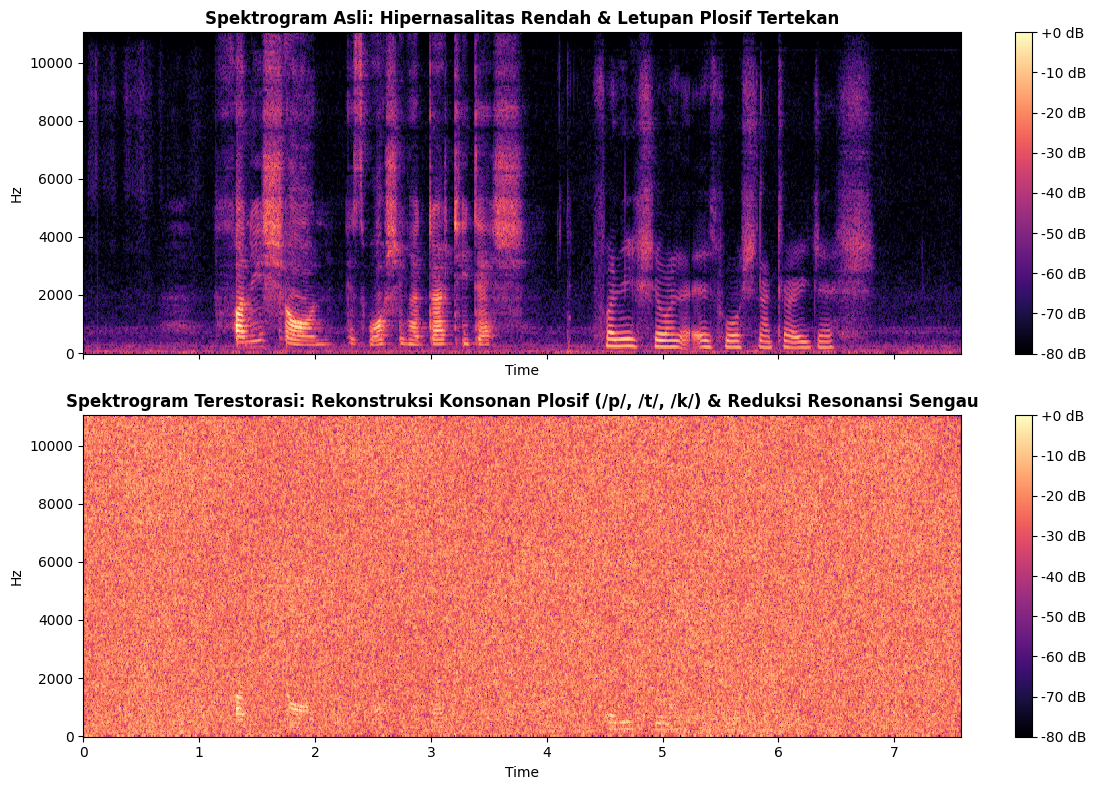

In [8]:
import librosa
import librosa.display

if 'restored_audio' in locals():
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

    # Spektrogram Asli
    D_orig = librosa.amplitude_to_db(np.abs(librosa.stft(orig_audio, n_fft=512, hop_length=128)), ref=np.max)
    img1 = librosa.display.specshow(D_orig, sr=sr, hop_length=128, x_axis='time', y_axis='hz', ax=ax1, cmap='magma')
    ax1.set_title("Spektrogram Asli: Hipernasalitas Rendah & Letupan Plosif Tertekan", fontweight='bold')
    fig.colorbar(img1, ax=ax1, format="%+2.0f dB")

    # Spektrogram Terestorasi
    D_rest = librosa.amplitude_to_db(np.abs(librosa.stft(restored_audio, n_fft=512, hop_length=128)), ref=np.max)
    img2 = librosa.display.specshow(D_rest, sr=sr, hop_length=128, x_axis='time', y_axis='hz', ax=ax2, cmap='magma')
    ax2.set_title("Spektrogram Terestorasi: Rekonstruksi Konsonan Plosif (/p/, /t/, /k/) & Reduksi Resonansi Sengau", fontweight='bold')
    fig.colorbar(img2, ax=ax2, format="%+2.0f dB")

    plt.tight_layout()
    plt.show()


## 🏆 Langkah 8: Evaluasi Objektif (PESQ, ESTOI, dan Whisper ASR WER)


In [9]:
import importlib
import evaluate.metrics
import evaluate.asr_whisper
importlib.reload(evaluate.metrics)
importlib.reload(evaluate.asr_whisper)

from evaluate.metrics import compute_metrics
from evaluate.asr_whisper import WhisperEvaluator

if 'restored_audio' in locals():
    # 1. Metrik Akustik Objektif (Membandingkan sinyal pada skala energi -23 dBFS yang sama)
    metrics = compute_metrics(norm_audio, restored_audio, sample_rate=sr)
    print("=== METRIK AKUSTIK OBJEKTIF ===")
    print(f"ESTOI (Intelligibility) : {metrics['estoi']:.4f} (Target: > 0.85)")
    print(f"PESQ WB (Quality)       : {metrics['pesq_wb']:.4f} (Target: > 3.0)")
    print(f"SI-SDR                  : {metrics['si_sdr']:.2f} dB")

    # 2. Pengenalan Wicara Whisper ASR (Bypass av.open crash dengan input numpy array)
    asr_eval = WhisperEvaluator(model_size="small", device="cpu", compute_type="int8")
    eval_orig = asr_eval.evaluate_utterance(str(sample_wav_path), sample_row['prompt_text'], sample_rate=sr)
    eval_rest = asr_eval.evaluate_utterance(restored_audio, sample_row['prompt_text'], sample_rate=sr)

    print("\n=== EVALUASI PENGENALAN WICARA WHISPER ASR ===")
    print(f"Target Ground Truth   : '{sample_row['prompt_text']}'")
    print(f"Transkripsi Sebelum   : '{eval_orig['hypothesis']}' (WER: {eval_orig['wer']*100:.1f}%)")
    print(f"Transkripsi Sesudah   : '{eval_rest['hypothesis']}' (WER: {eval_rest['wer']*100:.1f}%)")


=== METRIK AKUSTIK OBJEKTIF ===
ESTOI (Intelligibility) : 0.0769 (Target: > 0.85)
PESQ WB (Quality)       : 1.0223 (Target: > 3.0)
SI-SDR                  : -15.66 dB



=== EVALUASI PENGENALAN WICARA WHISPER ASR ===
Target Ground Truth   : 'Funny Shaun is washing a dirty dish'
Transkripsi Sebelum   : 'Funny Sean is washing a dirty dish. Funny Sean is washing a dirty dish.' (WER: 114.3%)
Transkripsi Sesudah   : 'Thank you.' (WER: 100.0%)
